In [ ]:
## part 1

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

%matplotlib inline

In [3]:
# Loading the  dataset
df = pd.read_csv(r"C:\Users\jforo\Downloads\amz_uk_price_prediction_dataset.csv")
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [6]:
df.isnull().sum().sort_values(ascending=False).head(50)

uid                  0
asin                 0
title                0
stars                0
reviews              0
price                0
isBestSeller         0
boughtInLastMonth    0
category             0
dtype: int64

In [7]:
# Separating between discrete and continuous variables, as discrete ones could potentially be treated as categorical.
# Remember to adjust the threshold (in this case, < 20) based on your dataset's specific characteristics and domain knowledge.
potential_categorical_from_numerical = df.select_dtypes("number").loc[:, df.select_dtypes("number").nunique() < 20]
potential_categorical_from_numerical

""
0
1
2
3
4
...
2443646
2443647
2443648
2443649


In [8]:
# Extracting columns with object (typically string) data types to create a categorical dataframe
# For demonstration purposes, let's consider the columns in potential_categorical_from_numerical as categorical variables.
df_categorical = pd.concat([df.select_dtypes("object"), potential_categorical_from_numerical], axis=1)

# Adjusting the numerical dataframe by removing the moved columns
df_numerical = df.select_dtypes("number").drop(columns=potential_categorical_from_numerical.columns)

In [ ]:
# crosstab

In [12]:
crosstab = pd.crosstab(df['category'], df['isBestSeller'], normalize='index')
crosstab

isBestSeller,False,True
category,,
3D Printers,0.995968,0.004032
3D Printing & Scanning,0.999508,0.000492
Abrasive & Finishing Products,0.980000,0.020000
Action Cameras,0.999411,0.000589
Adapters,0.988189,0.011811
...,...,...
Wind Instruments,0.972000,0.028000
Window Treatments,0.979079,0.020921
Women,0.988015,0.011985


In [13]:
crosstab.sort_values(by=True, ascending=False)

isBestSeller,False,True
category,,
Grocery,0.941865,0.058135
Smart Home Security & Lighting,0.942308,0.057692
Health & Personal Care,0.942314,0.057686
Mobile Phone Accessories,0.957529,0.042471
Power & Hand Tools,0.964661,0.035339
...,...,...
"CD, Disc & Tape Players",1.000000,0.000000
General Music-Making Accessories,1.000000,0.000000
Snowboard Boots,1.000000,0.000000


In [ ]:
# chi squared test

In [14]:
from scipy.stats import chi2_contingency

In [15]:
chi2_contingency(crosstab)

Chi2ContingencyResult(statistic=np.float64(3.9130707743346096), pvalue=np.float64(1.0), dof=295, expected_freq=array([[0.99383915, 0.00616085],
       [0.99383915, 0.00616085],
       [0.99383915, 0.00616085],
       [0.99383915, 0.00616085],
       [0.99383915, 0.00616085],
       [0.99383915, 0.00616085],
       [0.99383915, 0.00616085],
       [0.99383915, 0.00616085],
       [0.99383915, 0.00616085],
       [0.99383915, 0.00616085],
       [0.99383915, 0.00616085],
       [0.99383915, 0.00616085],
       [0.99383915, 0.00616085],
       [0.99383915, 0.00616085],
       [0.99383915, 0.00616085],
       [0.99383915, 0.00616085],
       [0.99383915, 0.00616085],
       [0.99383915, 0.00616085],
       [0.99383915, 0.00616085],
       [0.99383915, 0.00616085],
       [0.99383915, 0.00616085],
       [0.99383915, 0.00616085],
       [0.99383915, 0.00616085],
       [0.99383915, 0.00616085],
       [0.99383915, 0.00616085],
       [0.99383915, 0.00616085],
       [0.99383915, 0.00616085]

In [16]:
chi2_statistic, chi2_p_value, _, _ = chi2_contingency(crosstab)
chi2_statistic, chi2_p_value

(np.float64(3.9130707743346096), np.float64(1.0))

In [ ]:
# cramer

In [21]:
crosstab = pd.crosstab(df['category'], df['isBestSeller'])

In [22]:
from scipy.stats.contingency import association

In [23]:
# Computing the association between variables in 'crosstab_result' using the "cramer" method
association(crosstab, method="cramer")

0.1222829439760564

In [ ]:
# viz

<Axes: xlabel='category', ylabel='count'>

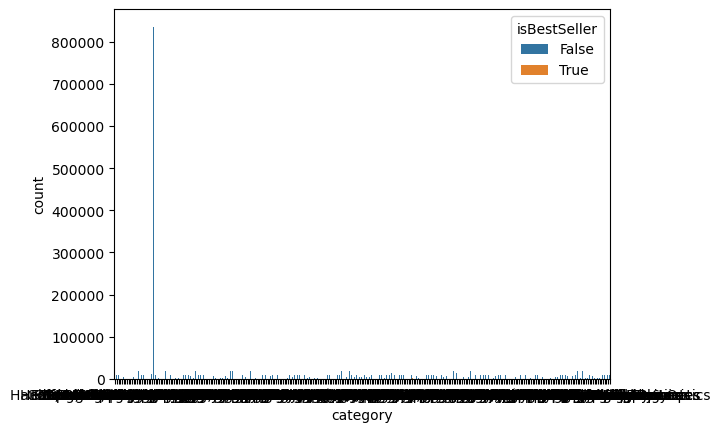

In [26]:
# Plotting a grouped bar chart
sns.countplot(data=df, x='category', hue='isBestSeller')

<Axes: xlabel='category'>

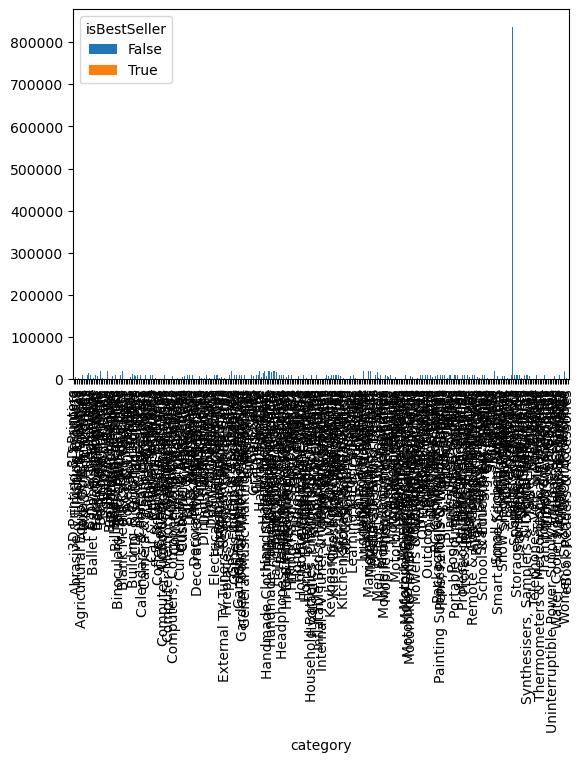

In [27]:
# Plotting a stacked bar chart for the 'crosstab' data
crosstab.plot(kind="bar", stacked=True)

In [ ]:
### Part 2

In [ ]:
## outliers

In [31]:
def tukeys_test_outliers(data):
    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)
    IQR = Q3 - Q1
    
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    outliers = data[(data < lower_bound) | (data > upper_bound)]
    
    return outliers, lower_bound, upper_bound

data_series = df['price']
outliers, lower_bound, upper_bound = tukeys_test_outliers(data_series)

# Remove rows where price is an outlier
df_clean = df[(df['price'] >= lower_bound) & (df['price'] <= upper_bound)]

10         139.00
19         164.99
25         149.99
28         289.00
31         199.99
            ...  
2443619    166.99
2443627    152.58
2443638    108.77
2443641    166.99
2443643    158.99
Name: price, Length: 327688, dtype: float64


In [ ]:
# violin plots

C:\Users\jforo\AppData\Local\Temp\ipykernel_22508\3520409153.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df, x='category', y='price', palette="coolwarm")


<Axes: xlabel='category', ylabel='price'>

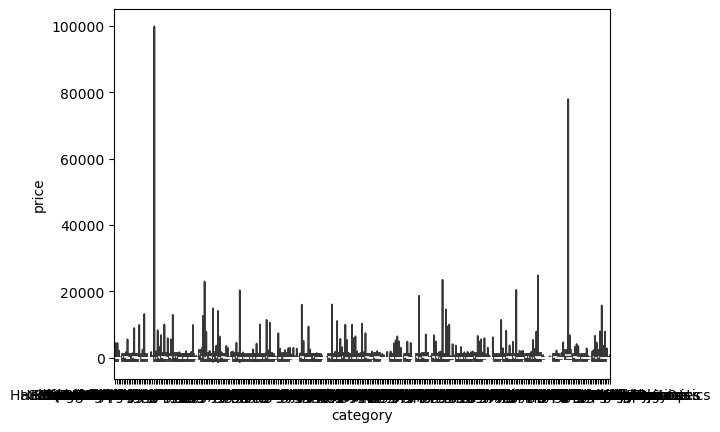

In [33]:
sns.violinplot(data=df, x='category', y='price', palette="coolwarm")

C:\Users\jforo\AppData\Local\Temp\ipykernel_22508\1166151912.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df_top20, x='category', y='price', palette="coolwarm")


([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19],
 [Text(0, 0, 'Handmade Home & Kitchen Products'),
  Text(1, 0, 'Sports & Outdoors'),
  Text(2, 0, 'Handmade Gifts'),
  Text(3, 0, 'Fragrances'),
  Text(4, 0, 'Skin Care'),
  Text(5, 0, 'Birthday Gifts'),
  Text(6, 0, 'Handmade Kitchen & Dining'),
  Text(7, 0, 'Bath & Body'),
  Text(8, 0, 'Manicure & Pedicure Products'),
  Text(9, 0, 'Beauty'),
  Text(10, 0, 'Handmade Artwork'),
  Text(11, 0, 'Make-up'),
  Text(12, 0, 'Baby'),
  Text(13, 0, 'Handmade Clothing, Shoes & Accessories'),
  Text(14, 0, 'Handmade Home Décor'),
  Text(15, 0, 'Men'),
  Text(16, 0, 'Luggage and travel gear'),
  Text(17, 0, 'Handmade Jewellery'),
  Text(18, 0, 'Women'),
  Text(19, 0, 'Hair Care')])

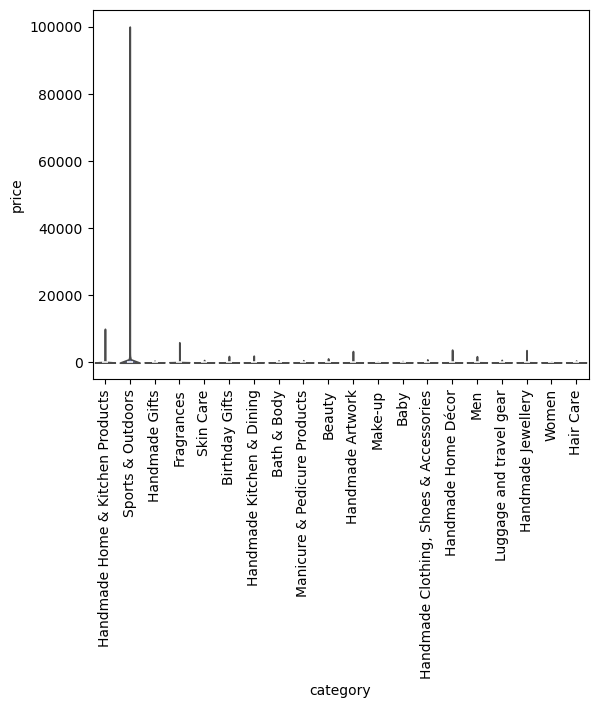

In [37]:
top20_categories = df['category'].value_counts().sort_values(ascending=False).head(20).index

df_top20 = df[df['category'].isin(top20_categories)]

sns.violinplot(data=df_top20, x='category', y='price', palette="coolwarm")
plt.xticks(rotation=90)

In [ ]:
# bar charts

C:\Users\jforo\AppData\Local\Temp\ipykernel_22508\896812745.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='category', y='price', palette="coolwarm")


<Axes: xlabel='category', ylabel='price'>

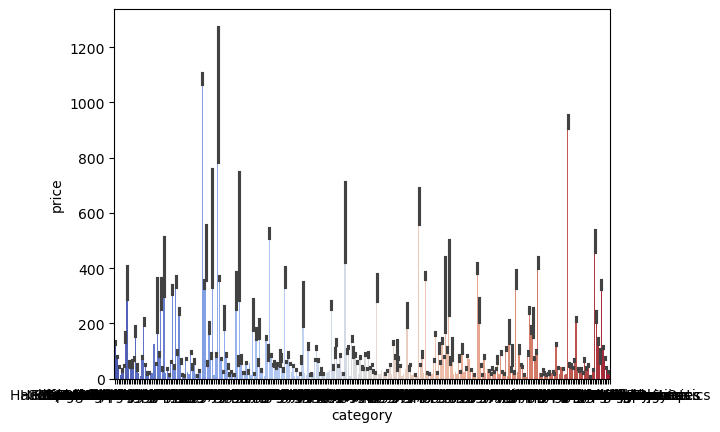

In [38]:
# Plotting a bar plot to visualize the average 'SalePrice' for each 'MSZoning' category, using the "coolwarm" color palette
sns.barplot(data=df, x='category', y='price', palette="coolwarm")

C:\Users\jforo\AppData\Local\Temp\ipykernel_22508\2869015395.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_top10, x='category', y='price', palette="coolwarm")


([0, 1, 2, 3, 4, 5, 6, 7, 8, 9],
 [Text(0, 0, 'Sports & Outdoors'),
  Text(1, 0, 'Fragrances'),
  Text(2, 0, 'Skin Care'),
  Text(3, 0, 'Birthday Gifts'),
  Text(4, 0, 'Bath & Body'),
  Text(5, 0, 'Manicure & Pedicure Products'),
  Text(6, 0, 'Beauty'),
  Text(7, 0, 'Make-up'),
  Text(8, 0, 'Handmade Clothing, Shoes & Accessories'),
  Text(9, 0, 'Hair Care')])

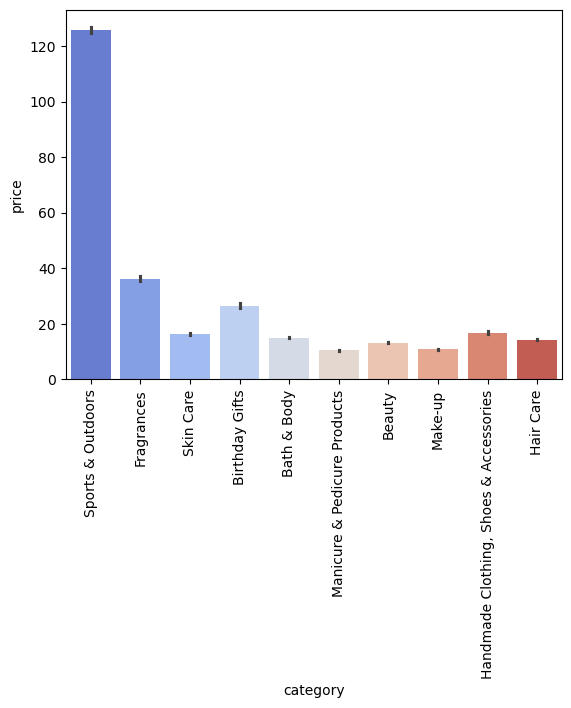

In [40]:
top10_categories = df['category'].value_counts().sort_values(ascending=False).head(10).index

df_top10 = df[df['category'].isin(top10_categories)]

sns.barplot(data=df_top10, x='category', y='price', palette="coolwarm")
plt.xticks(rotation=90)

In [ ]:
# Box Plots

C:\Users\jforo\AppData\Local\Temp\ipykernel_22508\1799382878.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_top10, x='category', y='stars', palette="coolwarm")


<Axes: xlabel='category', ylabel='stars'>

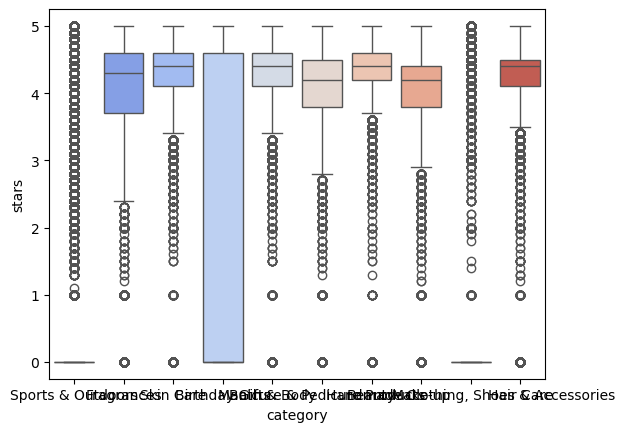

In [41]:
top10_categories = df['category'].value_counts().sort_values(ascending=False).head(10).index

df_top10 = df[df['category'].isin(top10_categories)]

sns.boxplot(data=df_top10, x='category', y='stars', palette="coolwarm")


In [ ]:
# part 3

In [ ]:
# Corr coef

In [42]:
# Calculating the Pearson correlation coefficient between 'price' and 'stars' columns
correlation = df['price'].corr(df['stars'])
correlation

np.float64(-0.1249067326214861)

In [ ]:
# scatter plot

<Axes: xlabel='stars', ylabel='price'>

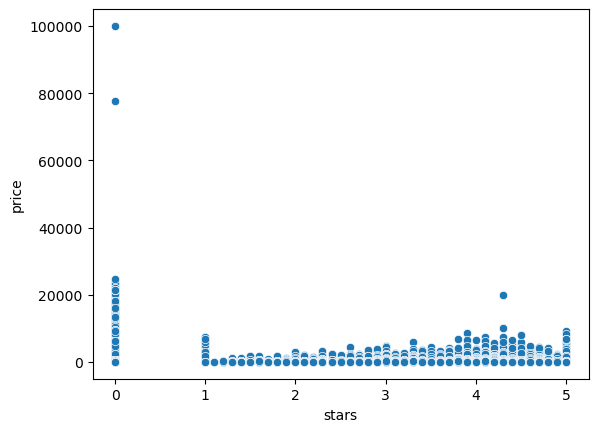

In [43]:
# Plotting a scatter plot to visualize the relationship between 'stars' and 'Price'
sns.scatterplot(data=df, x='stars', y='price')

In [ ]:
# heatmap

In [44]:
df_numerical = df.select_dtypes("number")

In [45]:
df_numerical.head(5)

,uid,stars,reviews,price,boughtInLastMonth
0,1,4.7,15308,21.99,0
1,2,4.7,98099,23.99,0
2,3,4.7,15308,21.99,0
3,4,4.7,7205,31.99,0
4,5,4.6,1881,17.99,0


In [49]:
df_numerical.drop("uid", inplace=True, axis=1)

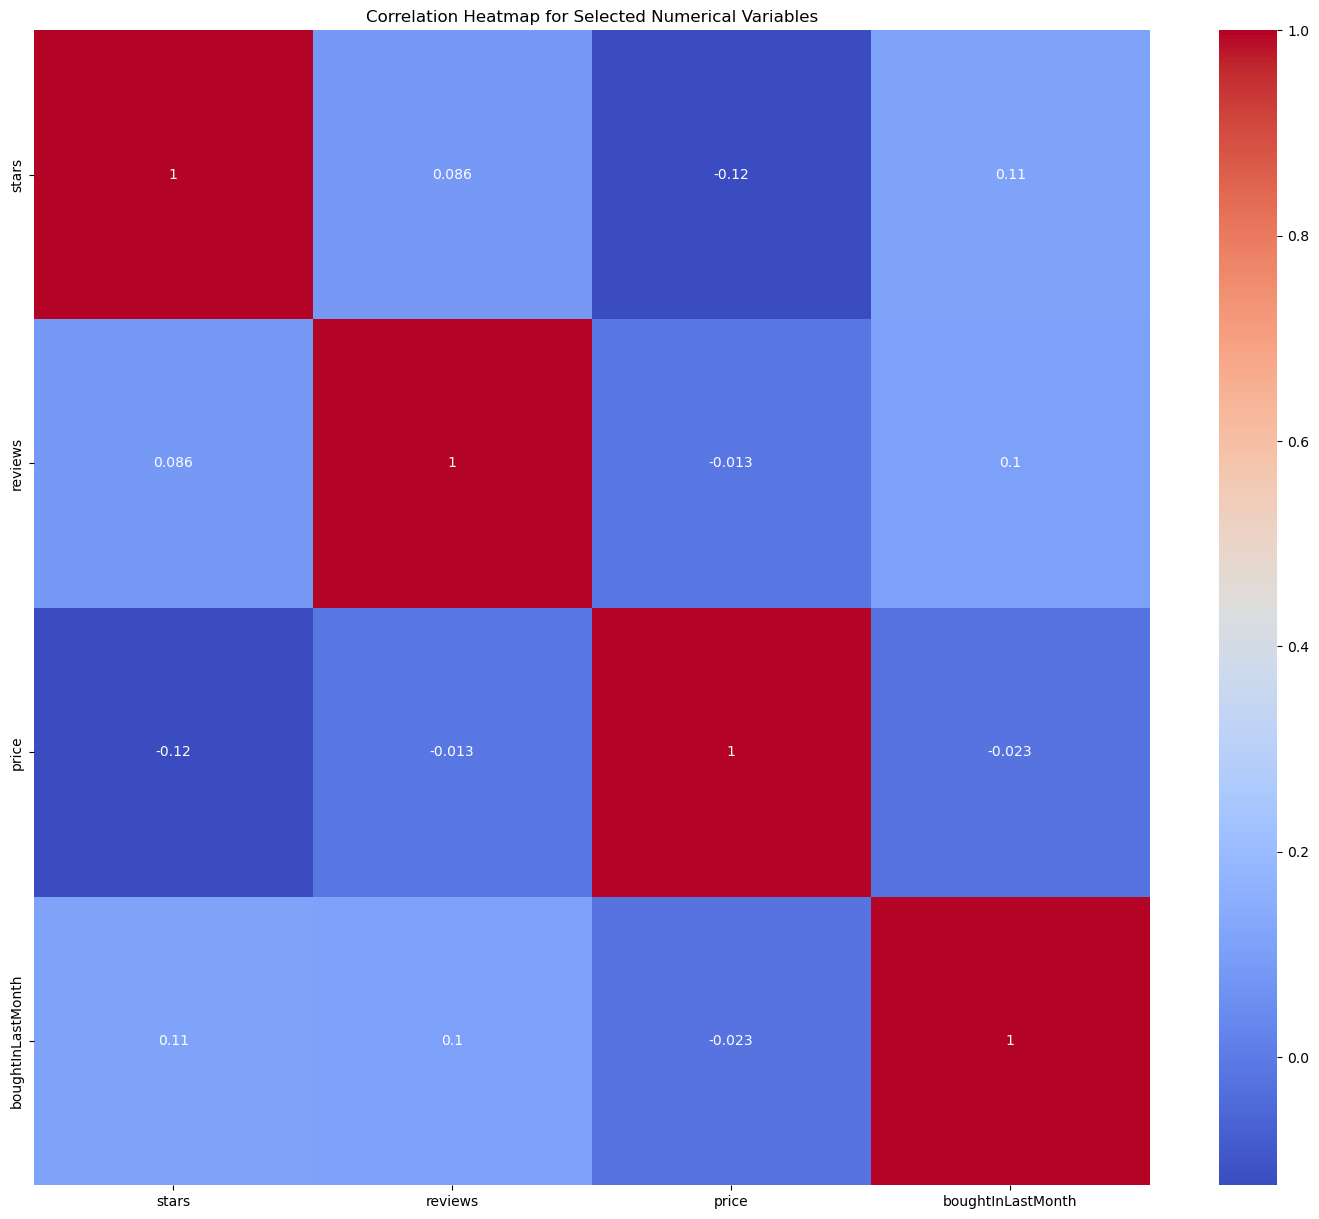

In [50]:
correlation_matrix = df_numerical.corr()

# Setting up the matplotlib figure with an appropriate size
plt.figure(figsize=(18, 15))

# Drawing the heatmap for the numerical columns
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm")

plt.title("Correlation Heatmap for Selected Numerical Variables")
plt.show()